# 07 — Train RGB + tracked-pose late-fusion model (full UCF101 sequence split)

This is the corrected replacement for `07_train_rgb_pose_fusion.ipynb`.

**Inputs**
- Full pose sequence arrays from the pointer written by Notebook 04 (`X_*.npy`, `y_*.npy`, `videos_*.npy`).
- The 512-D pretrained R3D-18 feature files created by Notebook 06 (`data/rgb_features_r3d18_v2`).

**Model**
- RGB branch: 512-D frozen R3D-18 Kinetics-400 video descriptor.
- Pose branch: tracked 17-joint sequences with confidence-masked velocity, acceleration and COCO-17 bone vectors, processed by a BiLSTM with temporal attention.
- Fusion: late feature concatenation and a classifier. This is **not** end-to-end RGB fine-tuning and does not directly reuse ST-GCN weights.

**Corrections in this version**
- Launches the worker with the same verified Anaconda Python used by Notebook 06, not `sys.executable` from the Jupyter kernel.
- Verifies every required RGB feature's shape, source video ID, path, label and split before training.
- Uses only classes with training windows; validation/test classes without training support are explicitly excluded from model evaluation and reported.
- Uses mild inverse-frequency class weights and video-level validation macro-F1 for checkpoint selection.
- Runs in a detached worker, logs progress to disk, saves the best and latest checkpoints every epoch plus recovery checkpoints every five epochs, and can resume after interruption.
- Uses a new `rgb_pose_fusion_v3_...` output directory; previous experiments are not overwritten.

**Run only after Notebook 06 reports 9,654 valid RGB feature files, zero missing features, and its worker has exited.** The RTX A4000 is required for this notebook's training worker.


In [3]:
# CELL 1 — Verify full pose/RGB inputs, CUDA and class support; prepare a fresh run directory.
from pathlib import Path
from datetime import datetime
import os, sys, json, hashlib, subprocess
import numpy as np
import pandas as pd

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
NOTEBOOK2_DIR = PROJECT_DIR / "Notebook_2_Improved_v2"

# Use the same Anaconda Python that successfully ran Notebook 06.
WORKER_PYTHON = Path(r"C:\Users\admin\anaconda3\python.exe")
assert WORKER_PYTHON.is_file(), f"Anaconda Python not found: {WORKER_PYTHON}"

PTR_PATH = NOTEBOOK2_DIR / "data" / "CURRENT_TRACKED_SEQUENCE_DIR.txt"
assert PTR_PATH.is_file(), "Run the corrected full-dataset Notebook 04 first."
SEQUENCE_DIR = Path(PTR_PATH.read_text(encoding="utf-8").strip())
assert SEQUENCE_DIR.is_dir(), f"Sequence dataset not found: {SEQUENCE_DIR}"

META_PATH = SEQUENCE_DIR / "dataset_metadata.json"
LABEL_MAP_PATH = SEQUENCE_DIR / "label_map.json"
SPLIT_MANIFEST_PATH = SEQUENCE_DIR / "video_split_manifest.csv"
for required_path in (META_PATH, LABEL_MAP_PATH, SPLIT_MANIFEST_PATH):
    assert required_path.is_file(), f"Required Notebook 04 file is missing: {required_path}"

META = json.loads(META_PATH.read_text(encoding="utf-8"))
assert META.get("is_full_dataset") is True, "The current sequence dataset is not marked as full."
assert float(META.get("source_video_coverage", 0)) == 1.0, "Pose source-video coverage is not 100%."

# Validate expected array shapes and build the set of videos actually used by sequences.
SPLIT_ARRAYS = {}
SEQUENCE_VIDEO_IDS = set()
SPLIT_VIDEO_IDS = {}
for split in ("train", "val", "test"):
    x_path = SEQUENCE_DIR / f"X_{split}.npy"
    y_path = SEQUENCE_DIR / f"y_{split}.npy"
    v_path = SEQUENCE_DIR / f"videos_{split}.npy"
    assert x_path.is_file() and y_path.is_file() and v_path.is_file(), f"Missing {split} arrays."
    X = np.load(x_path, mmap_mode="r", allow_pickle=False)
    y = np.load(y_path, mmap_mode="r", allow_pickle=False)
    videos = np.load(v_path, mmap_mode="r", allow_pickle=False)
    assert X.ndim == 3 and X.shape[1:] == (16, 51), f"{split}: expected [N,16,51], got {X.shape}"
    assert len(X) == len(y) == len(videos), f"{split}: X/y/videos lengths differ."
    assert len(X) > 0, f"{split}: no windows were generated."
    unique_ids = set(int(v) for v in np.unique(videos))
    SPLIT_VIDEO_IDS[split] = unique_ids
    SEQUENCE_VIDEO_IDS.update(unique_ids)
    SPLIT_ARRAYS[split] = {"X": X.shape, "y": y.shape, "videos": videos.shape}
    del X, y, videos

assert SEQUENCE_VIDEO_IDS, "No source video IDs are present in the sequence arrays."
assert not (SPLIT_VIDEO_IDS["train"] & SPLIT_VIDEO_IDS["val"]), "Train/validation video overlap."
assert not (SPLIT_VIDEO_IDS["train"] & SPLIT_VIDEO_IDS["test"]), "Train/test video overlap."
assert not (SPLIT_VIDEO_IDS["val"] & SPLIT_VIDEO_IDS["test"]), "Validation/test video overlap."

label_map_raw = json.loads(LABEL_MAP_PATH.read_text(encoding="utf-8"))
LABEL_MAP = {int(k): str(v) for k, v in label_map_raw.items()}

manifest = pd.read_csv(SPLIT_MANIFEST_PATH)
required_cols = {"video_id", "video_path", "label", "split"}
assert required_cols.issubset(manifest.columns), f"Split manifest missing: {required_cols - set(manifest.columns)}"
manifest["video_id"] = pd.to_numeric(manifest["video_id"], errors="raise").astype("int64")
manifest["video_path"] = manifest["video_path"].astype(str)
manifest["label"] = manifest["label"].astype(str)
manifest["split"] = manifest["split"].astype(str).str.lower()
assert not manifest["video_id"].duplicated().any(), "Duplicate video_id in the frozen split manifest."
manifest_by_id = manifest.set_index("video_id").to_dict(orient="index")

selected_rows = []
for video_id in sorted(SEQUENCE_VIDEO_IDS):
    if video_id not in manifest_by_id:
        raise RuntimeError(f"Sequence video_id {video_id} is absent from the frozen split manifest.")
    row = manifest_by_id[video_id]
    selected_rows.append({
        "video_id": int(video_id),
        "video_path": str(row["video_path"]),
        "label": str(row["label"]),
        "split": str(row["split"]),
    })
selected = pd.DataFrame(selected_rows)
assert selected["video_id"].nunique() == len(SEQUENCE_VIDEO_IDS)

# Verify the RGB worker is complete before using its outputs.
RGB_DIR = NOTEBOOK2_DIR / "data" / "rgb_features_r3d18_v2"
RGB_LOG_DIR = NOTEBOOK2_DIR / "logs" / "rgb_features_r3d18_v2"
RGB_STATE_PATH = RGB_LOG_DIR / "progress_state.json"
RGB_PID_PATH = RGB_LOG_DIR / "worker_pid.txt"
assert RGB_DIR.is_dir(), f"RGB feature folder not found: {RGB_DIR}"
assert RGB_STATE_PATH.is_file(), "Notebook 06 progress_state.json not found."
rgb_state = json.loads(RGB_STATE_PATH.read_text(encoding="utf-8"))
assert rgb_state.get("status") == "completed", f"Notebook 06 is not completed: {rgb_state.get('status')}"
assert int(rgb_state.get("total_videos", 0)) == 9654, f"Expected 9,654 RGB videos; state says {rgb_state.get('total_videos')}."
assert int(rgb_state.get("success", 0)) == 9654, f"RGB worker reports {rgb_state.get('success')} successful videos."
assert int(rgb_state.get("failed", 0)) == 0, f"RGB worker reports {rgb_state.get('failed')} failures."

# Refuse to train if the Notebook 06 worker process is still alive.
def get_process_command_line(pid):
    command = (
        f"$p = Get-CimInstance Win32_Process -Filter 'ProcessId = {int(pid)}' "
        f"-ErrorAction SilentlyContinue; if ($p) {{ $p.CommandLine }}"
    )
    try:
        result = subprocess.run(
            ["powershell", "-NoProfile", "-Command", command],
            capture_output=True, text=True, errors="replace", timeout=15
        )
        return (result.stdout or "").strip()
    except Exception:
        return ""

if RGB_PID_PATH.is_file():
    try:
        old_rgb_pid = int(RGB_PID_PATH.read_text(encoding="utf-8").strip())
    except Exception:
        old_rgb_pid = -1
    if old_rgb_pid > 0:
        old_rgb_cmd = get_process_command_line(old_rgb_pid)
        if old_rgb_cmd and "r3d18_feature_worker_v3.py" in old_rgb_cmd:
            raise RuntimeError(
                f"Notebook 06 worker PID {old_rgb_pid} is still alive. "
                "Wait for it to exit before launching fusion training."
            )

# Match Notebook 06's deterministic output filename exactly.
def expected_rgb_file(row):
    digest = hashlib.sha1(
        str(Path(row["video_path"]).resolve()).casefold().encode("utf-8")
    ).hexdigest()[:12]
    return RGB_DIR / f"video_{int(row['video_id']):06d}_{digest}.npz"

feature_index_rows = []
missing_features = []
invalid_features = []
for row in selected.to_dict("records"):
    feature_path = expected_rgb_file(row)
    if not feature_path.is_file():
        missing_features.append((row["video_id"], str(feature_path)))
        continue
    try:
        with np.load(feature_path, allow_pickle=False) as data:
            feature = np.asarray(data["feature"], dtype=np.float32)
            stored_id = int(np.asarray(data["video_id"]).item())
            stored_path = str(np.asarray(data["video_path"]).item())
            stored_label = str(np.asarray(data["label"]).item())
            stored_split = str(np.asarray(data["split"]).item()).lower()
            good = (
                feature.shape == (512,)
                and np.isfinite(feature).all()
                and stored_id == int(row["video_id"])
                and stored_path == row["video_path"]
                and stored_label == row["label"]
                and stored_split == row["split"]
            )
            if not good:
                invalid_features.append((row["video_id"], str(feature_path)))
                continue
        feature_index_rows.append({
            **row,
            "feature_path": str(feature_path),
        })
    except Exception as exc:
        invalid_features.append((row["video_id"], f"{feature_path}: {exc!r}"))

if missing_features or invalid_features:
    raise RuntimeError(
        f"RGB feature validation failed: missing={len(missing_features)}, invalid={len(invalid_features)}. "
        f"Missing examples={missing_features[:5]}; invalid examples={invalid_features[:5]}"
    )

FEATURE_INDEX_PATH = NOTEBOOK2_DIR / "data" / "rgb_features_r3d18_v2" / "rgb_feature_index_for_fusion.csv"
pd.DataFrame(feature_index_rows).to_csv(FEATURE_INDEX_PATH, index=False)

# Anaconda preflight: PyTorch, scikit-learn and CUDA must be available in the worker interpreter.
preflight_code = (
    "import sys, numpy, pandas, sklearn, torch; "
    "print('PYTHON=' + sys.executable); "
    "print('NUMPY=' + numpy.__version__); "
    "print('PANDAS=' + pandas.__version__); "
    "print('SKLEARN=' + sklearn.__version__); "
    "print('TORCH=' + torch.__version__); "
    "print('CUDA=' + str(torch.cuda.is_available())); "
    "print('GPU=' + (torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'UNAVAILABLE')); "
    "print('FREE_GB=' + (str(round(torch.cuda.mem_get_info(0)[0] / 1024**3, 2)) if torch.cuda.is_available() else '0'))"
)
preflight = subprocess.run(
    [str(WORKER_PYTHON), "-c", preflight_code],
    capture_output=True, text=True, errors="replace", timeout=120
)
print("ANACONDA FUSION WORKER PREFLIGHT:")
print(preflight.stdout)
if preflight.stderr.strip():
    print("Preflight stderr:", preflight.stderr[-2000:])
if preflight.returncode != 0 or "CUDA=True" not in preflight.stdout:
    raise RuntimeError("Anaconda PyTorch/CUDA preflight failed. Training was not launched.")

free_gb_match = [line for line in preflight.stdout.splitlines() if line.startswith("FREE_GB=")]
free_gpu_gb = float(free_gb_match[0].split("=", 1)[1]) if free_gb_match else 0.0
if free_gpu_gb < 3.0:
    raise RuntimeError(f"Only {free_gpu_gb:.2f} GB GPU memory is free. Wait for other GPU work to finish.")

# A stable run directory lets the worker resume from its last saved checkpoint after interruption.
RUN_DIR = NOTEBOOK2_DIR / "outputs" / "models" / f"rgb_pose_fusion_v3_{SEQUENCE_DIR.name}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
WORKER = NOTEBOOK2_DIR / "src" / "rgb_pose_fusion_worker_v3.py"
CONFIG_PATH = RUN_DIR / "worker_config.json"
PID_PATH = RUN_DIR / "fusion_worker.pid"
STATE_PATH = RUN_DIR / "progress_state.json"
STDOUT_PATH = RUN_DIR / "worker_stdout.log"
STDERR_PATH = RUN_DIR / "worker_stderr.log"

train_support = set()
for split in ("train", "val", "test"):
    y = np.load(SEQUENCE_DIR / f"y_{split}.npy", mmap_mode="r", allow_pickle=False)
    if split == "train":
        train_support = set(int(v) for v in np.unique(y))
    print(f"{split.upper()} windows: {len(y):,}; classes present: {len(np.unique(y))}")
    del y

print("\nRGB FEATURE COVERAGE VERIFIED")
print("Full pose sequence directory:", SEQUENCE_DIR)
print("Unique sequence source videos:", len(selected))
print("Validated RGB feature files:", len(feature_index_rows))
print("RGB failures/missing:", 0)
print("Classes with training windows:", len(train_support))
print("Classes without training windows:", sorted(LABEL_MAP[c] for c in LABEL_MAP if c not in train_support))
print("Feature index:", FEATURE_INDEX_PATH)
print("Fusion output directory:", RUN_DIR)
print("Worker Python:", WORKER_PYTHON)
print("GPU:", [line for line in preflight.stdout.splitlines() if line.startswith("GPU=")][0])


ANACONDA FUSION WORKER PREFLIGHT:
PYTHON=C:\Users\admin\anaconda3\python.exe
NUMPY=2.1.3
PANDAS=2.2.3
SKLEARN=1.6.1
TORCH=2.7.1+cu118
CUDA=True
GPU=NVIDIA RTX A4000
FREE_GB=14.9

TRAIN windows: 40,404; classes present: 100
VAL windows: 13,424; classes present: 99
TEST windows: 14,452; classes present: 99

RGB FEATURE COVERAGE VERIFIED
Full pose sequence directory: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\data\sequences_tracked_group_split_iou_v3_full_v1\20261031_035536
Unique sequence source videos: 9654
Validated RGB feature files: 9654
RGB failures/missing: 0
Classes with training windows: 100
Classes without training windows: ['BreastStroke']
Feature index: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\data\rgb_features_r3d18_v2\rgb_feature_index_for_fusion.csv
Fusion output directory: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\models\rgb_pose_fusion_v3_20261031_035536
Worker Python: C:\Users\admin\anaconda3\py

In [4]:
WORKER_SOURCE = r'''import os, sys, ctypes, json, time, random, gc, traceback
from pathlib import Path

# Load the PyTorch-bundled OpenMP runtime in this child process only.
torch_lib = Path(sys.prefix) / "Lib" / "site-packages" / "torch" / "lib"
_dll_handles = []
_openmp_handle = None
if os.name == "nt":
    iomp = torch_lib / "libiomp5md.dll"
    if iomp.is_file():
        try:
            _openmp_handle = ctypes.WinDLL(str(iomp))
            print("OPENMP_PRELOADED_FROM", iomp, flush=True)
        except OSError as exc:
            print("OPENMP_PRELOAD_WARNING", repr(exc), flush=True)
if torch_lib.is_dir():
    os.environ["PATH"] = str(torch_lib) + os.pathsep + os.environ.get("PATH", "")
    if hasattr(os, "add_dll_directory"):
        try:
            _dll_handles.append(os.add_dll_directory(str(torch_lib)))
        except OSError:
            pass

for name in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[name] = "1"
os.environ["PYTHONUNBUFFERED"] = "1"

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

def atomic_json(path, obj):
    path = Path(path)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    tmp.write_text(json.dumps(obj, indent=2), encoding="utf-8")
    os.replace(str(tmp), str(path))

def atomic_torch_save(obj, path):
    path = Path(path)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    torch.save(obj, tmp)
    os.replace(str(tmp), str(path))

def main(cfg):
    seed = int(cfg.get("seed", 42))
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(1)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    seq_dir = Path(cfg["sequence_dir"])
    rgb_dir = Path(cfg["rgb_dir"])
    run_dir = Path(cfg["run_dir"])
    index_csv = Path(cfg["feature_index_csv"])
    run_dir.mkdir(parents=True, exist_ok=True)

    if not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable in the Anaconda worker. Training was not started.")
    device = torch.device("cuda:0")
    gpu_name = torch.cuda.get_device_name(0)
    free_bytes, total_bytes = torch.cuda.mem_get_info(0)
    print(f"WORKER_PYTHON={sys.executable}", flush=True)
    print(f"DEVICE={device}; GPU={gpu_name}; FREE_GB={free_bytes / (1024**3):.2f}; TOTAL_GB={total_bytes / (1024**3):.2f}", flush=True)
    if free_bytes < int(cfg.get("minimum_free_gpu_gb", 3.0) * (1024**3)):
        raise RuntimeError(
            f"Only {free_bytes / (1024**3):.2f} GB GPU memory is free. "
            "Close other GPU workloads and relaunch; do not lower the safety check blindly."
        )

    metadata = json.loads((seq_dir / "dataset_metadata.json").read_text(encoding="utf-8"))
    if not metadata.get("is_full_dataset", False):
        raise RuntimeError("The sequence dataset is marked as partial.")
    label_map_raw = json.loads((seq_dir / "label_map.json").read_text(encoding="utf-8"))
    label_map = {int(k): str(v) for k, v in label_map_raw.items()}

    arrays = {}
    for split in ("train", "val", "test"):
        x = np.load(seq_dir / f"X_{split}.npy", mmap_mode="r", allow_pickle=False)
        y = np.load(seq_dir / f"y_{split}.npy", mmap_mode="r", allow_pickle=False)
        vids = np.load(seq_dir / f"videos_{split}.npy", mmap_mode="r", allow_pickle=False)
        if x.ndim != 3 or x.shape[1:] != (16, 51):
            raise ValueError(f"{split}: expected X shape [N,16,51], got {x.shape}")
        if len(x) != len(y) or len(y) != len(vids):
            raise ValueError(f"{split}: X/y/videos length mismatch")
        if len(x) == 0:
            raise ValueError(f"{split}: no sequences available")
        arrays[split] = {"X": x, "y": y, "videos": vids}

    # Output classes are restricted to classes with actual training windows.
    train_original_ids = sorted(int(x) for x in np.unique(arrays["train"]["y"]))
    if not train_original_ids:
        raise RuntimeError("No classes have training windows.")
    original_to_model = {orig: i for i, orig in enumerate(train_original_ids)}
    model_to_original = list(train_original_ids)
    n_classes = len(model_to_original)

    val_original_ids = sorted(int(x) for x in np.unique(arrays["val"]["y"]))
    test_original_ids = sorted(int(x) for x in np.unique(arrays["test"]["y"]))
    val_eval_original_ids = sorted(set(train_original_ids).intersection(val_original_ids))
    test_eval_original_ids = sorted(set(train_original_ids).intersection(test_original_ids))
    if not val_eval_original_ids:
        raise RuntimeError("No validation classes overlap with training classes.")
    if not test_eval_original_ids:
        raise RuntimeError("No test classes overlap with training classes.")

    # Load only the validated per-video RGB descriptors required by sequence windows.
    index_df = pd.read_csv(index_csv)
    required_cols = {"video_id", "feature_path", "video_path", "label", "split"}
    if not required_cols.issubset(index_df.columns):
        raise ValueError(f"Feature index is missing columns: {sorted(required_cols - set(index_df.columns))}")
    if index_df["video_id"].duplicated().any():
        raise ValueError("Duplicate video_id entries in validated RGB feature index.")
    rgb_by_video = {}
    for row in index_df.itertuples(index=False):
        with np.load(row.feature_path, allow_pickle=False) as data:
            feature = np.asarray(data["feature"], dtype=np.float32)
            if feature.shape != (512,) or not np.isfinite(feature).all():
                raise ValueError(f"Invalid 512-D RGB feature for video_id={row.video_id}")
            stored_id = int(np.asarray(data["video_id"]).item())
            stored_path = str(np.asarray(data["video_path"]).item())
            stored_label = str(np.asarray(data["label"]).item())
            stored_split = str(np.asarray(data["split"]).item()).lower()
            if stored_id != int(row.video_id):
                raise ValueError(f"RGB video_id mismatch in {row.feature_path}")
            if stored_path != str(row.video_path) or stored_label != str(row.label) or stored_split != str(row.split).lower():
                raise ValueError(f"RGB metadata mismatch for video_id={row.video_id}")
            rgb_by_video[stored_id] = feature.copy()

    for split in ("train", "val", "test"):
        missing = sorted(set(int(v) for v in np.unique(arrays[split]["videos"])) - set(rgb_by_video))
        if missing:
            raise RuntimeError(f"Missing RGB features for {len(missing)} {split} source videos. Example IDs: {missing[:10]}")

    class DatasetRGBPose(Dataset):
        def __init__(self, split):
            self.split = split
            self.x = arrays[split]["X"]
            self.y = arrays[split]["y"]
            self.videos = arrays[split]["videos"]
            # A class with no training windows cannot be learned. Exclude it from
            # model loss/metrics but record its support in the final report.
            self.indices = np.flatnonzero(np.isin(self.y, train_original_ids))
            if len(self.indices) == 0:
                raise ValueError(f"{split}: no windows belong to a class represented in training.")
        def __len__(self):
            return len(self.indices)
        def __getitem__(self, index):
            source_index = int(self.indices[index])
            pose = np.array(self.x[source_index], dtype=np.float32, copy=True)
            original_label = int(self.y[source_index])
            video_id = int(self.videos[source_index])
            rgb = rgb_by_video[video_id]
            return (
                torch.from_numpy(pose),
                torch.from_numpy(rgb.copy()),
                torch.tensor(original_to_model[original_label], dtype=torch.long),
                torch.tensor(video_id, dtype=torch.long),
            )

    batch_size = int(cfg["batch_size"])
    loaders = {
        split: DataLoader(
            DatasetRGBPose(split),
            batch_size=batch_size,
            shuffle=(split == "train"),
            num_workers=0,
            pin_memory=True,
            drop_last=False,
        )
        for split in ("train", "val", "test")
    }

    # COCO-17 parent links; one 9-channel feature vector per joint.
    PARENTS = [0, 0, 0, 1, 2, 0, 0, 5, 6, 7, 8, 5, 6, 11, 12, 13, 14]

    class FusionModel(nn.Module):
        def __init__(self, num_classes):
            super().__init__()
            self.pose_norm = nn.LayerNorm(17 * 9)
            self.pose_lstm = nn.LSTM(
                input_size=17 * 9, hidden_size=96, num_layers=1,
                batch_first=True, bidirectional=True
            )
            self.attention = nn.Sequential(nn.Linear(192, 96), nn.Tanh(), nn.Linear(96, 1))
            self.rgb_branch = nn.Sequential(
                nn.LayerNorm(512), nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.30)
            )
            self.classifier = nn.Sequential(
                nn.Linear(192 + 256, 256), nn.ReLU(),
                nn.Dropout(0.40), nn.Linear(256, num_classes)
            )

        def enrich_pose(self, pose):
            batch, timesteps, _ = pose.shape
            q = pose.reshape(batch, timesteps, 17, 3)
            xy = torch.nan_to_num(q[..., :2], nan=0.0, posinf=0.0, neginf=0.0)
            confidence = torch.nan_to_num(q[..., 2], nan=0.0, posinf=0.0, neginf=0.0)
            valid = confidence > 0
            velocity = torch.zeros_like(xy)
            acceleration = torch.zeros_like(xy)
            bones = torch.zeros_like(xy)

            if timesteps > 1:
                pair_valid = valid[:, 1:] & valid[:, :-1]
                delta = xy[:, 1:] - xy[:, :-1]
                velocity[:, 1:] = torch.where(pair_valid[..., None], delta, torch.zeros_like(delta))
            if timesteps > 2:
                triple_valid = valid[:, 2:] & valid[:, 1:-1] & valid[:, :-2]
                delta_velocity = velocity[:, 2:] - velocity[:, 1:-1]
                acceleration[:, 2:] = torch.where(
                    triple_valid[..., None], delta_velocity, torch.zeros_like(delta_velocity)
                )
            for joint, parent in enumerate(PARENTS):
                if joint == parent:
                    continue
                bone_valid = valid[:, :, joint] & valid[:, :, parent]
                vector = xy[:, :, joint] - xy[:, :, parent]
                bones[:, :, joint] = torch.where(
                    bone_valid[..., None], vector, torch.zeros_like(vector)
                )

            enriched = torch.cat([q, velocity, acceleration, bones], dim=-1)
            return torch.nan_to_num(enriched, nan=0.0, posinf=0.0, neginf=0.0).reshape(batch, timesteps, 17 * 9)

        def forward(self, pose, rgb):
            pose_features = self.enrich_pose(pose)
            temporal, _ = self.pose_lstm(self.pose_norm(pose_features))
            weights = torch.softmax(self.attention(temporal).squeeze(-1), dim=1)
            pose_embedding = (temporal * weights.unsqueeze(-1)).sum(dim=1)
            rgb_embedding = self.rgb_branch(rgb)
            return self.classifier(torch.cat([pose_embedding, rgb_embedding], dim=1))

    # Calculate mild inverse-frequency weights to reduce dominance by frequent classes.
    train_y_orig = np.asarray(arrays["train"]["y"], dtype=np.int64)
    train_y_model = np.asarray([original_to_model[int(v)] for v in train_y_orig], dtype=np.int64)
    counts = np.bincount(train_y_model, minlength=n_classes).astype(np.float64)
    if np.any(counts == 0):
        raise RuntimeError("Internal class mapping error: a train class has zero samples.")
    class_weights = np.sqrt(counts.mean() / counts)
    class_weights = np.clip(class_weights, 0.5, 3.0)
    class_weights = class_weights / class_weights.mean()
    weight_tensor = torch.tensor(class_weights, dtype=torch.float32, device=device)

    model = FusionModel(n_classes).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(cfg["learning_rate"]), weight_decay=float(cfg["weight_decay"])
    )
    criterion = nn.CrossEntropyLoss(weight=weight_tensor, label_smoothing=float(cfg["label_smoothing"]))
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=3
    )

    run_dir = Path(cfg["run_dir"])
    best_path = run_dir / "rgb_pose_fusion_best.pt"
    latest_path = run_dir / "latest_checkpoint.pt"
    history_path = run_dir / "training_history.csv"
    state_path = run_dir / "progress_state.json"
    max_epochs = int(cfg["epochs"])
    patience = int(cfg["patience"])
    best_score = -1.0
    best_epoch = 0
    stale_epochs = 0
    start_epoch = 1
    history_rows = []

    if history_path.is_file():
        try:
            history_rows = pd.read_csv(history_path).to_dict("records")
        except Exception:
            history_rows = []

    if latest_path.is_file():
        ckpt = torch.load(latest_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        if "scheduler_state" in ckpt:
            scheduler.load_state_dict(ckpt["scheduler_state"])
        start_epoch = int(ckpt["epoch"]) + 1
        best_score = float(ckpt.get("best_validation_video_macro_f1", -1.0))
        best_epoch = int(ckpt.get("best_epoch", 0))
        stale_epochs = int(ckpt.get("stale_epochs", 0))
        print(f"RESUMING_FROM_EPOCH={start_epoch}; BEST_EPOCH={best_epoch}; BEST_VAL_VIDEO_MACRO_F1={best_score:.4f}", flush=True)

    if (run_dir / "test_metrics.json").is_file() and not cfg.get("inference_only", False):
        print("FUSION_ALREADY_COMPLETE; existing test_metrics.json found. No retraining performed.", flush=True)
        return

    if start_epoch > max_epochs:
        if not best_path.is_file():
            raise RuntimeError("Maximum epochs reached but best checkpoint is missing.")
        print("Training checkpoints reached maximum epochs; running final evaluation.", flush=True)

    def mapped_metrics(y_true, y_pred, class_indices):
        labels = list(class_indices)
        if not labels:
            raise RuntimeError("No supported classes available for metric calculation.")
        return {
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "macro_f1_supported_classes": float(
                f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)
            ),
            "classes_in_macro_f1": int(len(labels)),
        }

    def aggregate_by_video(probabilities, y_true, video_ids):
        video_ids = np.asarray(video_ids, dtype=np.int64)
        y_true = np.asarray(y_true, dtype=np.int64)
        unique_videos, inverse = np.unique(video_ids, return_inverse=True)
        sums = np.zeros((len(unique_videos), probabilities.shape[1]), dtype=np.float64)
        np.add.at(sums, inverse, probabilities)
        counts_per_video = np.bincount(inverse, minlength=len(unique_videos))
        mean_probabilities = sums / counts_per_video[:, None]
        video_labels = np.empty(len(unique_videos), dtype=np.int64)
        for i in range(len(unique_videos)):
            labels_here = np.unique(y_true[inverse == i])
            if len(labels_here) != 1:
                raise ValueError(f"Source video {unique_videos[i]} has multiple labels within one split.")
            video_labels[i] = labels_here[0]
        return unique_videos, video_labels, mean_probabilities.argmax(axis=1), mean_probabilities

    def evaluate(loader, split_name):
        model.eval()
        y_true_parts, probability_parts, video_parts = [], [], []
        loss_total = 0.0
        n_total = 0
        with torch.inference_mode():
            for pose, rgb, target, video_id in loader:
                pose = pose.to(device, non_blocking=True)
                rgb = rgb.to(device, non_blocking=True)
                target = target.to(device, non_blocking=True)
                logits = model(pose, rgb)
                loss = criterion(logits, target)
                probs = torch.softmax(logits, dim=1).cpu().numpy()
                y_true_parts.append(target.cpu().numpy())
                probability_parts.append(probs)
                video_parts.append(video_id.numpy())
                loss_total += float(loss.item()) * len(target)
                n_total += len(target)
        y_true = np.concatenate(y_true_parts)
        probabilities = np.concatenate(probability_parts)
        video_ids = np.concatenate(video_parts)
        y_pred = probabilities.argmax(axis=1)
        supported_model_ids = sorted(set(int(v) for v in np.unique(y_true)))
        window_metrics = mapped_metrics(y_true, y_pred, supported_model_ids)
        unique_videos, video_y, video_pred, video_probs = aggregate_by_video(probabilities, y_true, video_ids)
        video_metrics = mapped_metrics(video_y, video_pred, supported_model_ids)
        return {
            "loss": loss_total / max(n_total, 1),
            "window_metrics": window_metrics,
            "video_metrics": video_metrics,
            "y_true": y_true,
            "y_pred": y_pred,
            "probabilities": probabilities,
            "video_ids": video_ids,
            "unique_videos": unique_videos,
            "video_y": video_y,
            "video_pred": video_pred,
            "video_probs": video_probs,
        }

    def train_one_epoch(loader):
        model.train()
        y_true_parts, y_pred_parts = [], []
        loss_total = 0.0
        n_total = 0
        for pose, rgb, target, _video_id in loader:
            pose = pose.to(device, non_blocking=True)
            rgb = rgb.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(pose, rgb)
            loss = criterion(logits, target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            loss_total += float(loss.item()) * len(target)
            n_total += len(target)
            y_true_parts.append(target.detach().cpu().numpy())
            y_pred_parts.append(logits.detach().argmax(dim=1).cpu().numpy())
        y_true = np.concatenate(y_true_parts)
        y_pred = np.concatenate(y_pred_parts)
        train_classes = sorted(set(int(v) for v in np.unique(y_true)))
        m = mapped_metrics(y_true, y_pred, train_classes)
        m["loss"] = loss_total / max(n_total, 1)
        return m

    val_model_class_ids = sorted(original_to_model[v] for v in val_eval_original_ids)

    if start_epoch <= max_epochs:
        for epoch in range(start_epoch, max_epochs + 1):
            t0 = time.time()
            train_metrics = train_one_epoch(loaders["train"])
            val_metrics = evaluate(loaders["val"], "val")
            val_score = float(val_metrics["video_metrics"]["macro_f1_supported_classes"])
            scheduler.step(val_score)

            row = {
                "epoch": epoch,
                "train_loss": train_metrics["loss"],
                "train_accuracy": train_metrics["accuracy"],
                "train_balanced_accuracy": train_metrics["balanced_accuracy"],
                "train_macro_f1_supported_classes": train_metrics["macro_f1_supported_classes"],
                "val_loss": val_metrics["loss"],
                "val_window_accuracy": val_metrics["window_metrics"]["accuracy"],
                "val_window_macro_f1": val_metrics["window_metrics"]["macro_f1_supported_classes"],
                "val_video_accuracy": val_metrics["video_metrics"]["accuracy"],
                "val_video_macro_f1": val_score,
                "learning_rate": float(optimizer.param_groups[0]["lr"]),
                "seconds": round(time.time() - t0, 2),
            }
            history_rows.append(row)
            pd.DataFrame(history_rows).to_csv(history_path, index=False)

            improved = val_score > best_score + 1e-6
            if improved:
                best_score = val_score
                best_epoch = epoch
                stale_epochs = 0
                atomic_torch_save({
                    "model_state": model.state_dict(),
                    "best_epoch": best_epoch,
                    "best_validation_video_macro_f1": best_score,
                    "model_to_original": model_to_original,
                    "label_map": label_map,
                    "architecture": "RGB R3D-18 clip descriptor + enriched pose BiLSTM attention late fusion",
                }, best_path)
            else:
                stale_epochs += 1

            checkpoint_obj = {
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict(),
                "best_validation_video_macro_f1": best_score,
                "best_epoch": best_epoch,
                "stale_epochs": stale_epochs,
                "model_to_original": model_to_original,
                "label_map": label_map,
            }
            atomic_torch_save(checkpoint_obj, latest_path)
            if epoch % 5 == 0:
                atomic_torch_save(checkpoint_obj, run_dir / f"recovery_epoch_{epoch:03d}.pt")

            state = {
                "status": "training",
                "epoch": epoch,
                "max_epochs": max_epochs,
                "best_epoch": best_epoch,
                "best_validation_video_macro_f1": best_score,
                "stale_epochs": stale_epochs,
                "train_accuracy": train_metrics["accuracy"],
                "train_macro_f1": train_metrics["macro_f1_supported_classes"],
                "val_window_accuracy": val_metrics["window_metrics"]["accuracy"],
                "val_video_accuracy": val_metrics["video_metrics"]["accuracy"],
                "val_video_macro_f1": val_score,
                "gpu_name": gpu_name,
                "device": str(device),
                "last_update": time.strftime("%Y-%m-%d %H:%M:%S"),
            }
            atomic_json(state_path, state)

            print(
                f"Epoch {epoch:02d}/{max_epochs} | "
                f"train_loss={train_metrics['loss']:.4f} train_acc={train_metrics['accuracy']:.4f} "
                f"train_F1={train_metrics['macro_f1_supported_classes']:.4f} | "
                f"val_loss={val_metrics['loss']:.4f} val_window_acc={val_metrics['window_metrics']['accuracy']:.4f} "
                f"val_video_acc={val_metrics['video_metrics']['accuracy']:.4f} "
                f"val_video_macroF1={val_score:.4f} | best={best_score:.4f}@{best_epoch} "
                f"| seconds={row['seconds']}",
                flush=True,
            )
            if device.type == "cuda":
                torch.cuda.empty_cache()
            gc.collect()
            if stale_epochs >= patience:
                print(f"EARLY_STOPPING at epoch {epoch}; patience={patience}", flush=True)
                break

    if not best_path.is_file():
        raise RuntimeError("No best validation checkpoint was saved.")
    best_checkpoint = torch.load(best_path, map_location=device, weights_only=False)
    model.load_state_dict(best_checkpoint["model_state"])
    test_result = evaluate(loaders["test"], "test")
        # Save video-level probabilities for ROC and Precision-Recall analysis
    np.save(run_dir / "video_probabilities.npy", test_result["video_probs"])
    np.save(run_dir / "video_true_labels.npy", test_result["video_y"])
    np.save(run_dir / "video_class_ids.npy",np.asarray(model_to_original, dtype=np.int64))

    print("VIDEO PROBABILITIES SAVED")
    print("Probability matrix:", test_result["video_probs"].shape)
    print("True labels:", test_result["video_y"].shape)

    # Convert model-index predictions back to original class IDs for interpretable reports.
    model_to_original_array = np.asarray(model_to_original, dtype=np.int64)
    test_true_orig = model_to_original_array[test_result["y_true"]]
    test_pred_orig = model_to_original_array[test_result["y_pred"]]
    video_true_orig = model_to_original_array[test_result["video_y"]]
    video_pred_orig = model_to_original_array[test_result["video_pred"]]

    test_model_classes = sorted(set(int(v) for v in np.unique(test_result["y_true"])))
    test_original_classes = [model_to_original[i] for i in test_model_classes]
    report_names = [label_map[i] for i in test_original_classes]
    class_report = classification_report(
        video_true_orig, video_pred_orig,
        labels=test_original_classes, target_names=report_names,
        output_dict=True, zero_division=0
    )
    pd.DataFrame(class_report).T.to_csv(run_dir / "video_classification_report.csv")

    pd.DataFrame(
        confusion_matrix(video_true_orig, video_pred_orig, labels=test_original_classes),
        index=report_names, columns=report_names
    ).to_csv(run_dir / "video_confusion_matrix.csv")

    window_report = classification_report(
        test_true_orig, test_pred_orig,
        labels=test_original_classes, target_names=report_names,
        output_dict=True, zero_division=0
    )
    pd.DataFrame(window_report).T.to_csv(run_dir / "window_classification_report.csv")

    video_predictions = pd.DataFrame({
        "video_id": test_result["unique_videos"],
        "true_label_id": video_true_orig,
        "true_label": [label_map[int(x)] for x in video_true_orig],
        "predicted_label_id": video_pred_orig,
        "predicted_label": [label_map[int(x)] for x in video_pred_orig],
        "num_windows": [
            int(np.sum(test_result["video_ids"] == vid)) for vid in test_result["unique_videos"]
        ],
    })
    video_predictions.to_csv(run_dir / "video_predictions.csv", index=False)

    window_predictions = pd.DataFrame({
        "video_id": test_result["video_ids"],
        "true_label_id": test_true_orig,
        "true_label": [label_map[int(x)] for x in test_true_orig],
        "predicted_label_id": test_pred_orig,
        "predicted_label": [label_map[int(x)] for x in test_pred_orig],
    })
    window_predictions.to_csv(run_dir / "window_predictions.csv", index=False)

    all_test_original_ids = sorted(int(x) for x in np.unique(arrays["test"]["y"]))
    test_without_train = sorted(set(all_test_original_ids) - set(train_original_ids))
    val_without_train = sorted(set(val_original_ids) - set(train_original_ids))

    final_metrics = {
        "experiment": "late RGB + enriched tracked-pose fusion",
        "description": "512-D pretrained R3D-18 video descriptor plus pose BiLSTM attention with confidence-masked velocity, acceleration and COCO-17 bone vectors; video-level mean-probability aggregation.",
        "best_epoch": int(best_checkpoint["best_epoch"]),
        "best_validation_video_macro_f1_supported_classes": float(best_checkpoint["best_validation_video_macro_f1"]),
        "train_windows": int(len(arrays["train"]["y"])),
        "validation_windows": int(len(arrays["val"]["y"])),
        "test_windows": int(len(arrays["test"]["y"])),
        "test_videos": int(len(test_result["unique_videos"])),
        "classes_in_model": int(n_classes),
        "test_classes_evaluated": int(len(test_original_classes)),
        "test_classes_without_training_support": [label_map[x] for x in test_without_train],
        "validation_classes_without_training_support": [label_map[x] for x in val_without_train],
        "window_metrics": mapped_metrics(
            test_result["y_true"], test_result["y_pred"], test_model_classes
        ),
        "video_metrics": mapped_metrics(
            test_result["video_y"], test_result["video_pred"], test_model_classes
        ),
        "checkpoint": str(best_path),
        "device": str(device),
        "gpu_name": gpu_name,
        "rgb_feature_dimension": 512,
        "pose_sequence_shape": [16, 51],
        "model_class_ids_original": model_to_original,
    }
    atomic_json(run_dir / "test_metrics.json", final_metrics)
    atomic_json(state_path, {
        "status": "completed",
        "epoch": int(best_checkpoint["best_epoch"]),
        "max_epochs": max_epochs,
        "best_epoch": int(best_checkpoint["best_epoch"]),
        "best_validation_video_macro_f1": best_score,
        "test_video_accuracy": final_metrics["video_metrics"]["accuracy"],
        "test_video_macro_f1": final_metrics["video_metrics"]["macro_f1_supported_classes"],
        "gpu_name": gpu_name,
        "device": str(device),
        "last_update": time.strftime("%Y-%m-%d %H:%M:%S"),
    })
    print("RGB_POSE_FUSION_COMPLETE", json.dumps(final_metrics, indent=2), flush=True)

if __name__ == "__main__":
    try:
        if len(sys.argv) != 2:
            raise RuntimeError("Usage: rgb_pose_fusion_worker_v3.py <config.json>")
        cfg = json.loads(Path(sys.argv[1]).read_text(encoding="utf-8"))
        main(cfg)
    except BaseException as exc:
        print("FUSION_WORKER_EXCEPTION", repr(exc), flush=True)
        traceback.print_exc()
        sys.exit(2)
'''

# Compile-check before writing/launching; this catches syntax errors without starting training.
compile(WORKER_SOURCE, str(WORKER), "exec")
WORKER.parent.mkdir(parents=True, exist_ok=True)
WORKER.write_text(WORKER_SOURCE, encoding="utf-8")

CONFIG = {
    "sequence_dir": str(SEQUENCE_DIR),
    "rgb_dir": str(RGB_DIR),
    "feature_index_csv": str(FEATURE_INDEX_PATH),
    "run_dir": str(RUN_DIR),
    "batch_size": 8,
    "epochs": 0,
    "patience": 8,
    "learning_rate": 0.0003,
    "weight_decay": 0.001,
    "label_smoothing": 0.03,
    "minimum_free_gpu_gb": 3.0,
    "seed": 42,
    "inference_only": True,
}
CONFIG_PATH.write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
print("Fusion worker created and syntax-checked:", WORKER)
print("Configuration saved:", CONFIG_PATH)
print("Batch size:", CONFIG["batch_size"], "| Max epochs:", CONFIG["epochs"], "| Patience:", CONFIG["patience"])


Fusion worker created and syntax-checked: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\src\rgb_pose_fusion_worker_v3.py
Configuration saved: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\models\rgb_pose_fusion_v3_20261031_035536\worker_config.json
Batch size: 8 | Max epochs: 0 | Patience: 8


In [5]:
# CELL 3 — Launch exactly one detached fusion worker.
import subprocess, os, time

def query_process_command_line(pid):
    command = (
        f"$p = Get-CimInstance Win32_Process -Filter 'ProcessId = {int(pid)}' "
        f"-ErrorAction SilentlyContinue; if ($p) {{ $p.CommandLine }}"
    )
    try:
        result = subprocess.run(
            ["powershell", "-NoProfile", "-Command", command],
            capture_output=True, text=True, errors="replace", timeout=15
        )
        return (result.stdout or "").strip()
    except Exception:
        return ""

if (RUN_DIR / "test_metrics.json").is_file() and not CONFIG.get("inference_only", False):
    print("Fusion test metrics already exist. No worker launched and no retraining performed.")
else:
    if PID_PATH.is_file():
        try:
            old_pid = int(PID_PATH.read_text(encoding="utf-8").strip())
        except Exception:
            old_pid = -1
        if old_pid > 0:
            old_cmd = query_process_command_line(old_pid)
            if old_cmd and "rgb_pose_fusion_worker_v3.py" in old_cmd:
                raise RuntimeError(
                    f"Fusion worker PID {old_pid} is already running. "
                    "Do not start a duplicate; use Cell 4 to monitor it."
                )

    env = os.environ.copy()
    for key in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
        env[key] = "1"
    torch_lib = WORKER_PYTHON.parent / "Lib" / "site-packages" / "torch" / "lib"
    if torch_lib.is_dir():
        env["PATH"] = str(torch_lib) + os.pathsep + env.get("PATH", "")
    env["PYTHONUNBUFFERED"] = "1"

    RUN_DIR.mkdir(parents=True, exist_ok=True)
    stdout_file = open(STDOUT_PATH, "a", encoding="utf-8", buffering=1)
    stderr_file = open(STDERR_PATH, "a", encoding="utf-8", buffering=1)
    creationflags = 0
    if os.name == "nt":
        creationflags = subprocess.CREATE_NEW_PROCESS_GROUP | subprocess.DETACHED_PROCESS
    try:
        proc = subprocess.Popen(
            [str(WORKER_PYTHON), str(WORKER), str(CONFIG_PATH)],
            cwd=str(PROJECT_DIR),
            env=env,
            stdout=stdout_file,
            stderr=stderr_file,
            creationflags=creationflags,
            close_fds=True,
        )
    finally:
        stdout_file.close()
        stderr_file.close()
    PID_PATH.write_text(str(proc.pid), encoding="utf-8")
    print("RGB + pose fusion worker launched.")
    print("Worker PID:", proc.pid)
    print("Worker Python:", WORKER_PYTHON)
    print("GPU: NVIDIA CUDA (cuda:0)")
    print("Output directory:", RUN_DIR)
    print("Stdout:", STDOUT_PATH)
    print("Stderr:", STDERR_PATH)
    print("Use Cell 4 to monitor. Do not rerun Cell 3 while this worker is alive.")


RGB + pose fusion worker launched.
Worker PID: 27312
Worker Python: C:\Users\admin\anaconda3\python.exe
GPU: NVIDIA CUDA (cuda:0)
Output directory: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\models\rgb_pose_fusion_v3_20261031_035536
Stdout: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\models\rgb_pose_fusion_v3_20261031_035536\worker_stdout.log
Stderr: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\models\rgb_pose_fusion_v3_20261031_035536\worker_stderr.log
Use Cell 4 to monitor. Do not rerun Cell 3 while this worker is alive.


In [6]:
# CELL 4 — Read-only fusion training monitor. Safe to rerun.
import json, subprocess

STATE_PATH = RUN_DIR / "progress_state.json"

def is_worker_alive(pid):
    if pid <= 0:
        return False
    command = (
        f"$p = Get-CimInstance Win32_Process -Filter 'ProcessId = {int(pid)}' "
        f"-ErrorAction SilentlyContinue; if ($p) {{ $p.CommandLine }}"
    )
    try:
        result = subprocess.run(
            ["powershell", "-NoProfile", "-Command", command],
            capture_output=True, text=True, errors="replace", timeout=15
        )
        return "rgb_pose_fusion_worker_v3.py" in (result.stdout or "")
    except Exception as exc:
        print("Could not query worker process:", repr(exc))
        return False

if PID_PATH.is_file():
    try:
        worker_pid = int(PID_PATH.read_text(encoding="utf-8").strip())
    except Exception:
        worker_pid = -1
    print("Worker PID:", worker_pid)
    print("Worker alive:", is_worker_alive(worker_pid))
else:
    print("Worker PID file has not been created.")

if STATE_PATH.is_file():
    state = json.loads(STATE_PATH.read_text(encoding="utf-8"))
    print("\nCURRENT FUSION STATE")
    print(json.dumps(state, indent=2))
else:
    print("\nWorker state has not been written yet. Check worker_stdout.log.")

for title, path in (("STDOUT", STDOUT_PATH), ("STDERR", STDERR_PATH)):
    if path.is_file() and path.stat().st_size:
        print(f"\nLATEST {title} (last 35 lines)")
        lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
        for line in lines[-35:]:
            print(line)

metrics_path = RUN_DIR / "test_metrics.json"
if metrics_path.is_file():
    print("\nFINAL TEST METRICS")
    print(json.dumps(json.loads(metrics_path.read_text(encoding="utf-8")), indent=2))


Worker PID: 27312
Worker alive: False

CURRENT FUSION STATE
{
  "status": "completed",
  "epoch": 12,
  "max_epochs": 0,
  "best_epoch": 12,
  "best_validation_video_macro_f1": 0.8351999774732446,
  "test_video_accuracy": 0.8558929490478642,
  "test_video_macro_f1": 0.8343410715137116,
  "gpu_name": "NVIDIA RTX A4000",
  "device": "cuda:0",
  "last_update": "2026-11-01 03:33:47"
}

LATEST STDOUT (last 35 lines)
    68,
    69,
    70,
    71,
    72,
    73,
    74,
    75,
    76,
    77,
    78,
    79,
    80,
    81,
    82,
    83,
    84,
    85,
    86,
    87,
    88,
    89,
    90,
    91,
    92,
    93,
    94,
    95,
    96,
    97,
    98,
    99,
    100
  ]
}

LATEST STDERR (last 35 lines)
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\admin\anaconda3\Lib\site-p

In [10]:
# CELL 5 — Final metrics, history, class report and saved files.
import json
import pandas as pd

metrics_path = RUN_DIR / "test_metrics.json"
history_path = RUN_DIR / "training_history.csv"
report_path = RUN_DIR / "video_classification_report.csv"
confusion_path = RUN_DIR / "video_confusion_matrix.csv"

if metrics_path.is_file():
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    print("FINAL RGB + POSE FUSION TEST METRICS")
    print(json.dumps(metrics, indent=2))
else:
    print("Final test metrics are not present yet. Wait for the worker to finish.")

if history_path.is_file():
    history = pd.read_csv(history_path)
    print("\nTRAINING HISTORY (last 15 epochs)")
    display(history.tail(15))
else:
    print("Training history not created yet.")

if report_path.is_file():
    print("\nVIDEO-LEVEL CLASSIFICATION REPORT")
    display(pd.read_csv(report_path, index_col=0))
else:
    print("Video classification report not created yet.")

if confusion_path.is_file():
    print("\nVIDEO-LEVEL CONFUSION MATRIX")
    display(pd.read_csv(confusion_path, index_col=0))
else:
    print("Video confusion matrix not created yet.")

print("\nRUN DIRECTORY:", RUN_DIR)
for name in (
    "rgb_pose_fusion_best.pt",
    "latest_checkpoint.pt",
    "training_history.csv",
    "test_metrics.json",
    "video_classification_report.csv",
    "video_confusion_matrix.csv",
    "window_classification_report.csv",
    "video_predictions.csv",
    "window_predictions.csv",
    "progress_state.json",
    "worker_stdout.log",
    "worker_stderr.log",
):
    path = RUN_DIR / name
    print(f"{name}: {'PRESENT' if path.is_file() else 'not created yet'}")


FINAL RGB + POSE FUSION TEST METRICS
{
  "experiment": "late RGB + enriched tracked-pose fusion",
  "description": "512-D pretrained R3D-18 video descriptor plus pose BiLSTM attention with confidence-masked velocity, acceleration and COCO-17 bone vectors; video-level mean-probability aggregation.",
  "best_epoch": 12,
  "best_validation_video_macro_f1_supported_classes": 0.8351999774732446,
  "train_windows": 40404,
  "validation_windows": 13424,
  "test_windows": 14452,
  "test_videos": 1943,
  "classes_in_model": 100,
  "test_classes_evaluated": 99,
  "test_classes_without_training_support": [],
  "validation_classes_without_training_support": [],
  "window_metrics": {
    "accuracy": 0.8360088569056185,
    "balanced_accuracy": 0.8349776113886009,
    "macro_f1_supported_classes": 0.8079590080457276,
    "classes_in_macro_f1": 99
  },
  "video_metrics": {
    "accuracy": 0.8558929490478642,
    "balanced_accuracy": 0.8421678976788705,
    "macro_f1_supported_classes": 0.834341071513

,epoch,train_loss,train_accuracy,train_balanced_accuracy,train_macro_f1_supported_classes,val_loss,val_window_accuracy,val_window_macro_f1,val_video_accuracy,val_video_macro_f1,learning_rate,seconds
5,6,0.473241,0.998218,0.988384,0.990993,1.141946,0.832986,0.783577,0.832822,0.804043,0.000300,66.34
6,7,0.464833,0.998762,0.990620,0.992501,1.131243,0.838796,0.796964,0.840491,0.819299,0.000300,64.53
7,8,0.460982,0.998837,0.989546,0.992684,1.178543,0.816895,0.773321,0.829243,0.809646,0.000300,66.85
8,9,0.456187,0.999158,0.994317,0.995689,1.172954,0.828516,0.790155,0.837935,0.821397,0.000150,65.34
9,10,0.445113,0.999579,0.995266,0.996872,1.161266,0.834774,0.798906,0.842025,0.820444,0.000150,66.35
10,11,0.441472,0.999752,0.997347,0.998244,1.173097,0.828516,0.788274,0.841002,0.817552,0.000150,66.50
11,12,0.439737,0.999653,0.996060,0.997338,1.151324,0.843564,0.815008,0.851738,0.835200,0.000150,66.43
12,13,0.438664,0.999827,0.998301,0.998875,1.162279,0.826877,0.792382,0.836401,0.818781,0.000150,66.26
13,14,0.436913,0.999777,0.998102,0.998577,1.146073,0.834029,0.802486,0.842025,0.823107,0.000150,65.62
14,15,0.435586,0.999802,0.998160,0.998780,1.144765,0.841627,0.798563,0.846115,0.822623,0.000150,67.32



VIDEO-LEVEL CLASSIFICATION REPORT


,precision,recall,f1-score,support
ApplyEyeMakeup,0.828571,0.966667,0.892308,30.000000
ApplyLipstick,0.923077,0.500000,0.648649,24.000000
Archery,0.722222,0.590909,0.650000,22.000000
BabyCrawling,1.000000,0.850000,0.918919,20.000000
BalanceBeam,0.777778,0.875000,0.823529,8.000000
...,...,...,...,...
WritingOnBoard,0.967742,0.967742,0.967742,31.000000
YoYo,0.923077,0.888889,0.905660,27.000000
accuracy,0.855893,0.855893,0.855893,0.855893
macro avg,0.850584,0.842168,0.834341,1943.000000



VIDEO-LEVEL CONFUSION MATRIX


,ApplyEyeMakeup,ApplyLipstick,Archery,BabyCrawling,BalanceBeam,BandMarching,BaseballPitch,Basketball,BasketballDunk,BenchPress,...,TennisSwing,ThrowDiscus,TrampolineJumping,Typing,UnevenBars,VolleyballSpiking,WalkingWithDog,WallPushups,WritingOnBoard,YoYo
ApplyEyeMakeup,29,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ApplyLipstick,6,12,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Archery,0,0,13,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BabyCrawling,0,0,0,17,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
BalanceBeam,0,0,0,0,7,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
VolleyballSpiking,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,13,0,0,0,0
WalkingWithDog,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,23,0,0,0
WallPushups,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,28,0,0
WritingOnBoard,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,30,0



RUN DIRECTORY: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\models\rgb_pose_fusion_v3_20261031_035536
rgb_pose_fusion_best.pt: PRESENT
latest_checkpoint.pt: PRESENT
training_history.csv: PRESENT
test_metrics.json: PRESENT
video_classification_report.csv: PRESENT
video_confusion_matrix.csv: PRESENT
window_classification_report.csv: PRESENT
video_predictions.csv: PRESENT
window_predictions.csv: PRESENT
progress_state.json: PRESENT
worker_stdout.log: PRESENT
worker_stderr.log: PRESENT


## Run order and interpretation

1. Confirm Notebook 06 reported **9,654 valid RGB features, 0 missing, 0 failed**, and that its worker process has exited.
2. Run Cell 1. It validates the full pose sequences, every required 512-D RGB feature file, source video IDs/paths/labels/splits, Anaconda dependencies and CUDA availability.
3. Run Cell 2 once to write and syntax-check the complete worker.
4. Run Cell 3 once to launch training. It refuses to launch a duplicate worker.
5. Rerun Cell 4 to monitor progress. It is read-only.
6. Run Cell 5 after the worker reports `completed` to inspect test metrics and reports.

**Do not run Notebook 08 until `test_metrics.json` exists.**

### Important methodological notes
- This is late fusion of a frozen 512-D R3D-18 clip descriptor and a learned enriched-pose BiLSTM branch. It is not a synchronized two-stream network and does not directly reuse ST-GCN weights.
- RGB descriptors are one vector per source video and are reused by all pose windows from that video.
- The model has output classes only for labels that have training windows. Classes absent from training (currently BreastStroke) cannot be learned and are reported as unsupported.
- Validation and test windows for any class without training support are excluded from model loss/metrics and reported explicitly. No data is moved between splits.
- Checkpoint selection uses validation **video-level supported-class macro-F1**. Final metrics include both window-level and video-level results.
- Batch size is 8; checkpoints are saved every epoch, with additional recovery checkpoints every five epochs. If interrupted, rerun Cells 1–3 using the same current sequence pointer and run directory; the worker resumes from `latest_checkpoint.pt`.


PROBABILITY FILES VERIFIED
Probability shape: (1943, 100)
True label shape: (1943,)
Class mapping shape: (100,)


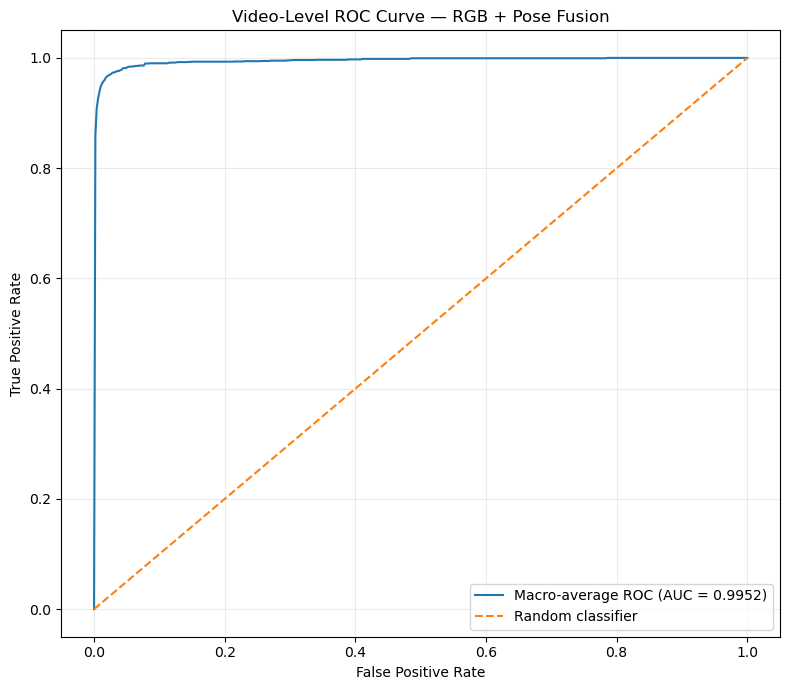

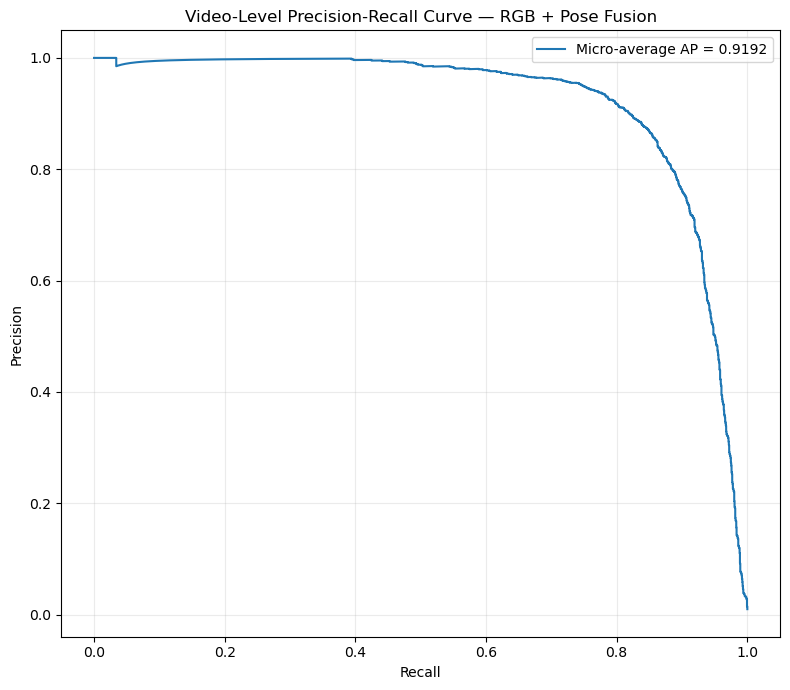


OVERALL CURVE METRICS
                         Metric    Value
          Macro-average ROC-AUC 0.995159
          Micro-average ROC-AUC 0.995722
Macro-average Average Precision 0.914554
Micro-average Average Precision 0.919160

TOP 10 ROC-AUC CLASSES
 class_id     class_name  support  ROC_AUC
        8 BasketballDunk        3      1.0
       10         Biking       14      1.0
        9     BenchPress       22      1.0
       30   FrisbeeCatch       12      1.0
       32      GolfSwing       26      1.0
       25         Diving        3      1.0
       13 BlowingCandles       14      1.0
       15        Bowling       16      1.0
       26       Drumming       22      1.0
       20   CleanAndJerk       21      1.0

LOWEST 10 ROC-AUC CLASSES
 class_id       class_name  support  ROC_AUC
       68      PommelHorse       11 0.937653
       95       UnevenBars        9 0.945249
       92      ThrowDiscus       15 0.947026
       14 BodyWeightSquats       17 0.953179
       23      CricketS

In [7]:
# CELL 5 — Generate video-level ROC and Precision-Recall analysis
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    roc_curve, auc, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# --------------------------------------------------
# 1. Load saved inference results
# --------------------------------------------------
prob_path = RUN_DIR / "video_probabilities.npy"
true_path = RUN_DIR / "video_true_labels.npy"
class_path = RUN_DIR / "video_class_ids.npy"

for path in [prob_path, true_path, class_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

probabilities = np.load(prob_path)
y_true = np.load(true_path).astype(int)
class_ids = np.load(class_path).astype(int)

print("PROBABILITY FILES VERIFIED")
print("Probability shape:", probabilities.shape)
print("True label shape:", y_true.shape)
print("Class mapping shape:", class_ids.shape)

assert probabilities.shape[0] == len(y_true)
assert probabilities.shape[1] == len(class_ids)
assert np.isfinite(probabilities).all()
assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-4)

# --------------------------------------------------
# 2. Prepare one-vs-rest class evaluation
# --------------------------------------------------
n_classes = probabilities.shape[1]
y_binary = np.eye(n_classes, dtype=int)[y_true]

label_map_path = SEQUENCE_DIR / "label_map.json"
label_map_raw = json.loads(label_map_path.read_text(encoding="utf-8"))
label_map = {int(k): str(v) for k, v in label_map_raw.items()}

roc_rows = []
pr_rows = []
roc_curves = []

for i in range(n_classes):
    positives = int(y_binary[:, i].sum())
    negatives = len(y_true) - positives

    # ROC requires both positive and negative examples.
    if positives == 0 or negatives == 0:
        continue

    fpr, tpr, _ = roc_curve(y_binary[:, i], probabilities[:, i])
    roc_auc = auc(fpr, tpr)

    precision, recall, _ = precision_recall_curve(
        y_binary[:, i], probabilities[:, i]
    )
    ap = average_precision_score(y_binary[:, i], probabilities[:, i])

    original_id = int(class_ids[i])
    class_name = label_map.get(original_id, str(original_id))

    roc_rows.append({
        "class_id": original_id,
        "class_name": class_name,
        "support": positives,
        "ROC_AUC": roc_auc
    })

    pr_rows.append({
        "class_id": original_id,
        "class_name": class_name,
        "support": positives,
        "Average_Precision": ap
    })

    roc_curves.append((fpr, tpr))

roc_df = pd.DataFrame(roc_rows)
pr_df = pd.DataFrame(pr_rows)

# --------------------------------------------------
# 3. Calculate macro and micro summary values
# --------------------------------------------------
macro_auc = roc_df["ROC_AUC"].mean()
macro_ap = pr_df["Average_Precision"].mean()

micro_auc = roc_auc_score(
    y_binary.ravel(), probabilities.ravel()
)
micro_ap = average_precision_score(
    y_binary.ravel(), probabilities.ravel()
)

summary = pd.DataFrame([
    {"Metric": "Macro-average ROC-AUC", "Value": macro_auc},
    {"Metric": "Micro-average ROC-AUC", "Value": micro_auc},
    {"Metric": "Macro-average Average Precision", "Value": macro_ap},
    {"Metric": "Micro-average Average Precision", "Value": micro_ap},
])

# --------------------------------------------------
# 4. Plot macro-average ROC curve
# --------------------------------------------------
mean_fpr = np.linspace(0, 1, 500)
interpolated_tprs = []

for fpr, tpr in roc_curves:
    interpolated_tprs.append(np.interp(mean_fpr, fpr, tpr))

mean_tpr = np.mean(interpolated_tprs, axis=0)
mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0

plt.figure(figsize=(8, 7))
plt.plot(
    mean_fpr, mean_tpr,
    label=f"Macro-average ROC (AUC = {macro_auc:.4f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Video-Level ROC Curve — RGB + Pose Fusion")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RUN_DIR / "roc_curve.png", dpi=300)
plt.show()

# --------------------------------------------------
# 5. Plot micro-average Precision-Recall curve
# --------------------------------------------------
precision_micro, recall_micro, _ = precision_recall_curve(
    y_binary.ravel(), probabilities.ravel()
)

plt.figure(figsize=(8, 7))
plt.plot(
    recall_micro, precision_micro,
    label=f"Micro-average AP = {micro_ap:.4f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Video-Level Precision-Recall Curve — RGB + Pose Fusion")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RUN_DIR / "precision_recall_curve.png", dpi=300)
plt.show()

# --------------------------------------------------
# 6. Save numerical tables
# --------------------------------------------------
roc_df.to_csv(RUN_DIR / "video_roc_auc.csv", index=False)
pr_df.to_csv(RUN_DIR / "video_average_precision.csv", index=False)
summary.to_csv(RUN_DIR / "video_curve_summary.csv", index=False)

print("\nOVERALL CURVE METRICS")
print(summary.to_string(index=False))

print("\nTOP 10 ROC-AUC CLASSES")
print(roc_df.sort_values("ROC_AUC", ascending=False).head(10).to_string(index=False))

print("\nLOWEST 10 ROC-AUC CLASSES")
print(roc_df.sort_values("ROC_AUC").head(10).to_string(index=False))

print("\nALL OUTPUTS SAVED TO:", RUN_DIR)